In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import data_loaders

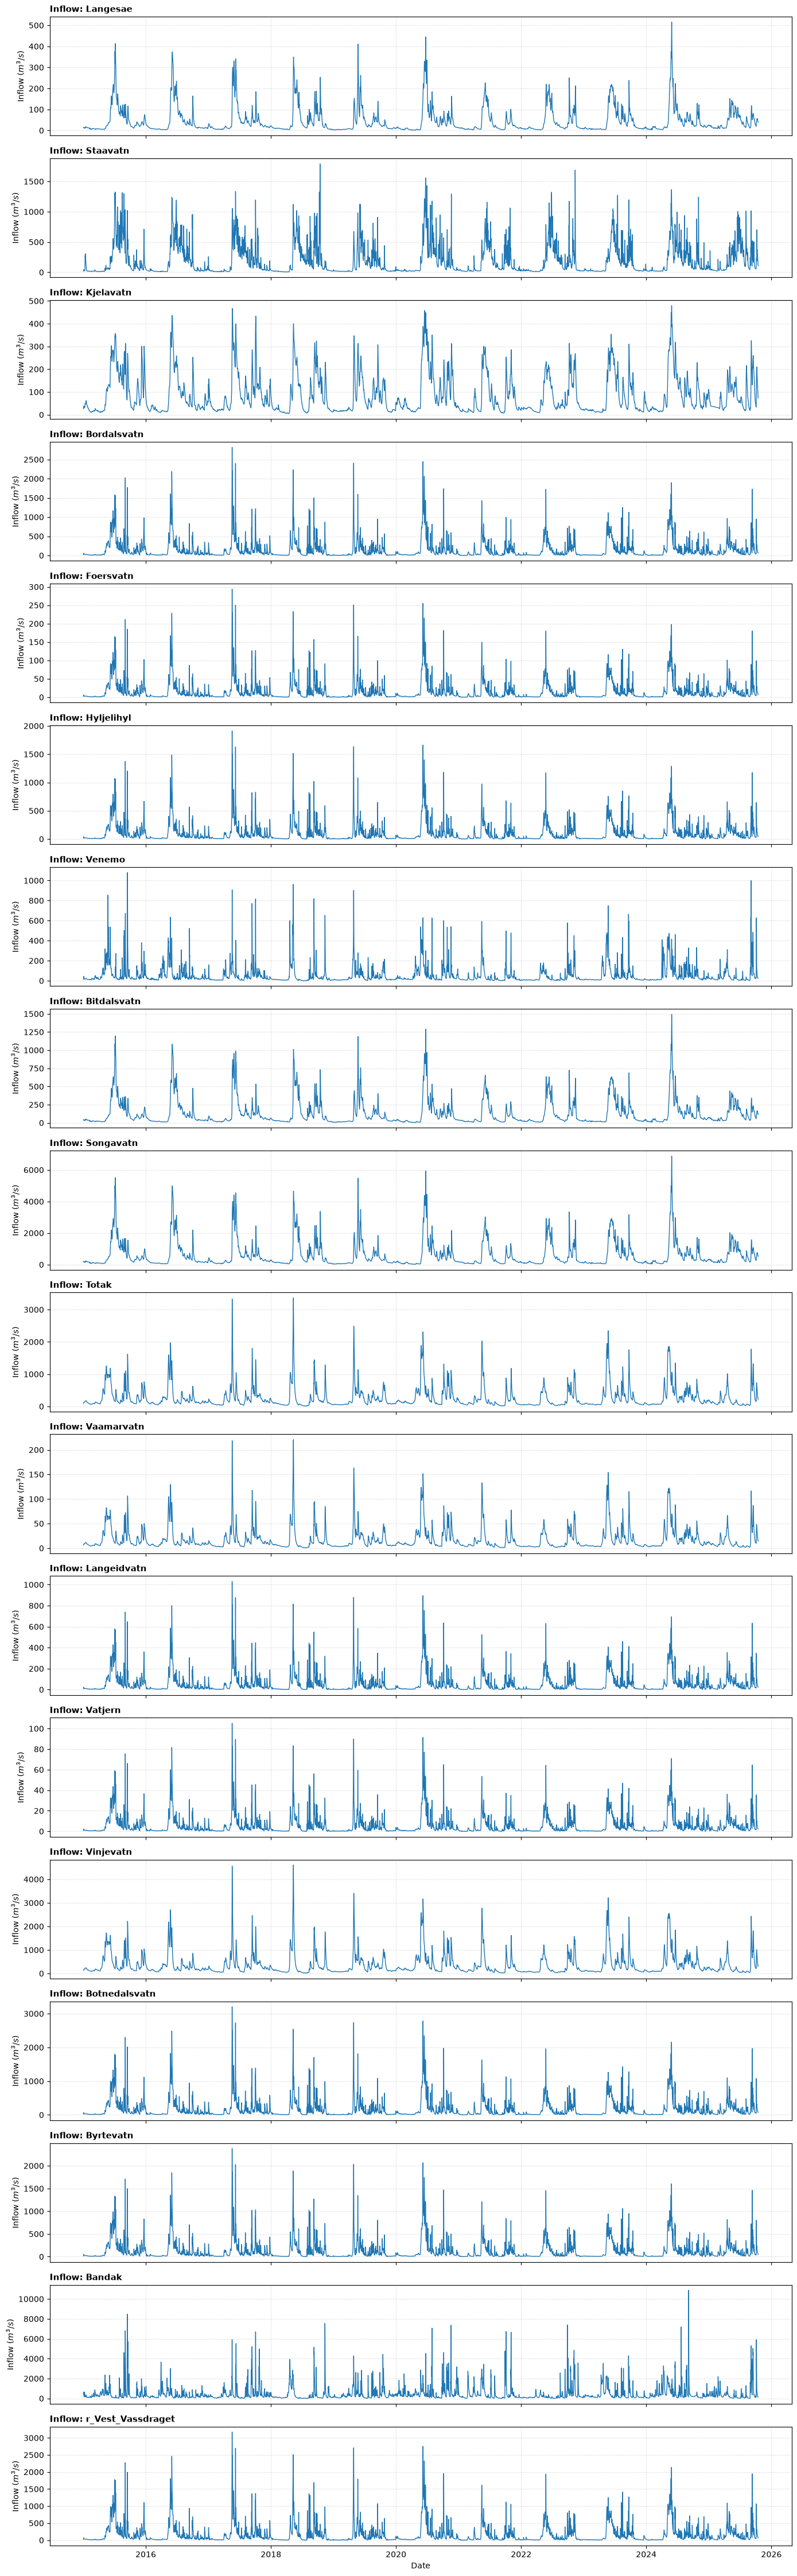

In [2]:
# Rolling inflow sums (3 and 7 days).

data = data_loaders.DataLoader()
d2 = data.inflow_data.copy()

if 'date' in d2.columns:
    d2.set_index('date', inplace=True)
if not isinstance(d2.index, pd.DatetimeIndex):
    d2.index = pd.to_datetime(d2.index)
if d2.index.tz is not None:
    d2.index = d2.index.tz_localize(None)
d2 = d2.loc['2015-01-01':]

# Set window in hours
d2 = d2.rolling(window=24*7).sum()

num_reservoirs = len(d2.columns)
fig, axes = plt.subplots(num_reservoirs, 1, figsize=(14, 2.5 * num_reservoirs), sharex=True)

for ax, col in zip(axes, d2.columns):
    ax.plot(d2.index, d2[col], color='tab:blue', linewidth=1)
    ax.set_title(f'Inflow: {col}', fontsize=11, fontweight='bold', loc='left')
    ax.set_ylabel('Inflow ($m^3/s$)')
    ax.grid(True, linestyle=':', alpha=0.6)

plt.xlabel('Date')
plt.tight_layout()
plt.show()

In [3]:
# Hour/Day/Week/Month etc.

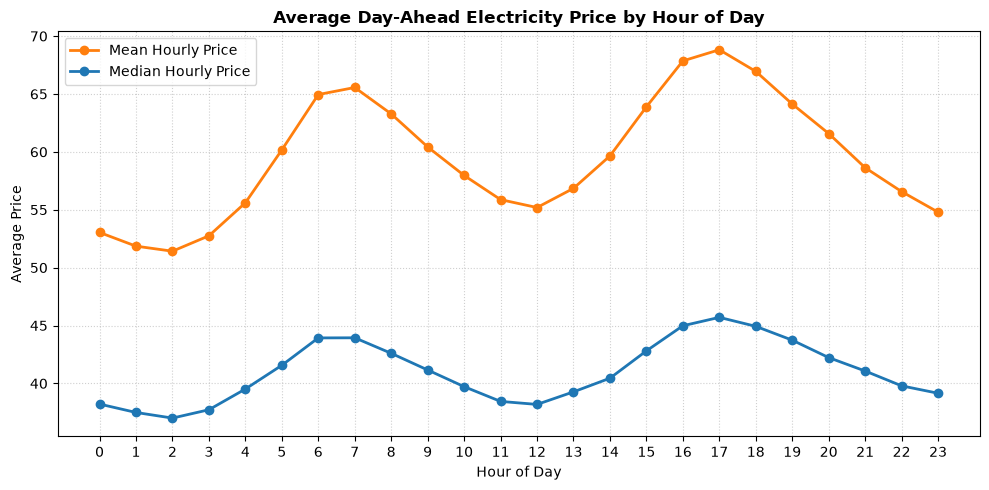

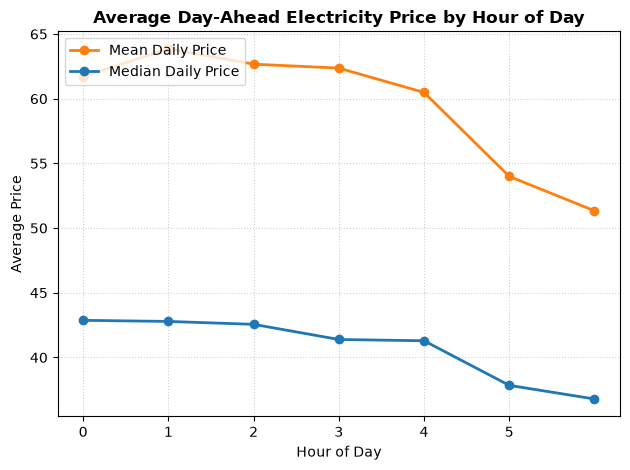

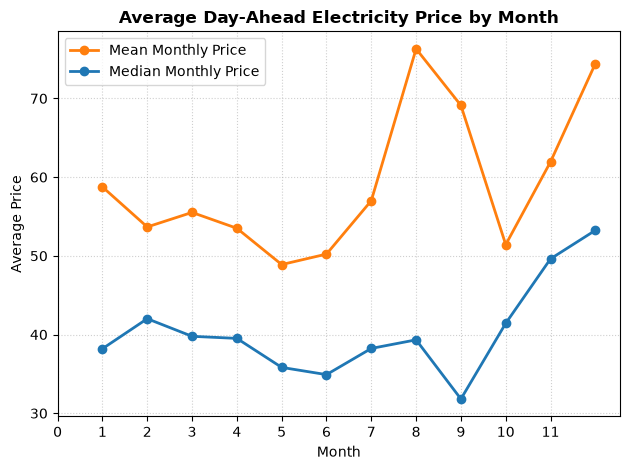

In [15]:
# Price
data = data_loaders.DataLoader()
d = data.day_ahead_price_data.copy()

if 'date' in d.columns:
    d.set_index('date', inplace=True)
if not isinstance(d.index, pd.DatetimeIndex):
    d.index = pd.to_datetime(d.index)
if d.index.tz is not None:
    d.index = d.index.tz_localize(None)

d = d.loc['2015-01-01':]
price_col = [col for col in d.columns if col != 'date'][0]

# HOUR OF DAY
hourly_profile_mean = d.groupby(d.index.hour)[price_col].mean()
hourly_profile_median = d.groupby(d.index.hour)[price_col].median()

plt.figure(figsize=(10, 5))
plt.plot(
    hourly_profile_mean.index, 
    hourly_profile_mean.values, 
    marker='o', 
    color='tab:orange', 
    linewidth=2, 
    markersize=6,
    label='Mean Hourly Price'
)
plt.plot(
    hourly_profile_median.index, 
    hourly_profile_median.values, 
    marker='o', 
    color='tab:blue', 
    linewidth=2, 
    markersize=6,
    label='Median Hourly Price'
)

plt.title('Average Day-Ahead Electricity Price by Hour of Day', fontsize=12, fontweight='bold')
plt.xlabel('Hour of Day')
plt.ylabel('Average Price')
plt.xticks(range(0, 24))
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

# DAY OF WEEK
daily_profile_mean = d.groupby(d.index.dayofweek)[price_col].mean()
daily_profile_median = d.groupby(d.index.dayofweek)[price_col].median()

plt.plot(
    daily_profile_mean.index, 
    daily_profile_mean.values, 
    marker='o', 
    color='tab:orange', 
    linewidth=2, 
    markersize=6,
    label='Mean Daily Price'
)
plt.plot(
    daily_profile_median.index, 
    daily_profile_median.values, 
    marker='o', 
    color='tab:blue', 
    linewidth=2, 
    markersize=6,
    label='Median Daily Price'
)

plt.title('Average Day-Ahead Electricity Price by Hour of Day', fontsize=12, fontweight='bold')
plt.xlabel('Hour of Day')
plt.ylabel('Average Price')
plt.xticks(range(0, 6))
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

# MONTH OF YEAR

monthly_profile_mean = d.groupby(d.index.month)[price_col].mean()
monthly_profile_median = d.groupby(d.index.month)[price_col].median()

plt.plot(
    monthly_profile_mean.index, 
    monthly_profile_mean.values, 
    marker='o', 
    color='tab:orange', 
    linewidth=2, 
    markersize=6,
    label='Mean Monthly Price'
)
plt.plot(
    monthly_profile_median.index, 
    monthly_profile_median.values, 
    marker='o', 
    color='tab:blue', 
    linewidth=2, 
    markersize=6,
    label='Median Monthly Price'
)
plt.title('Average Day-Ahead Electricity Price by Month', fontsize=12, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Average Price')
plt.xticks(range(0, 12))
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

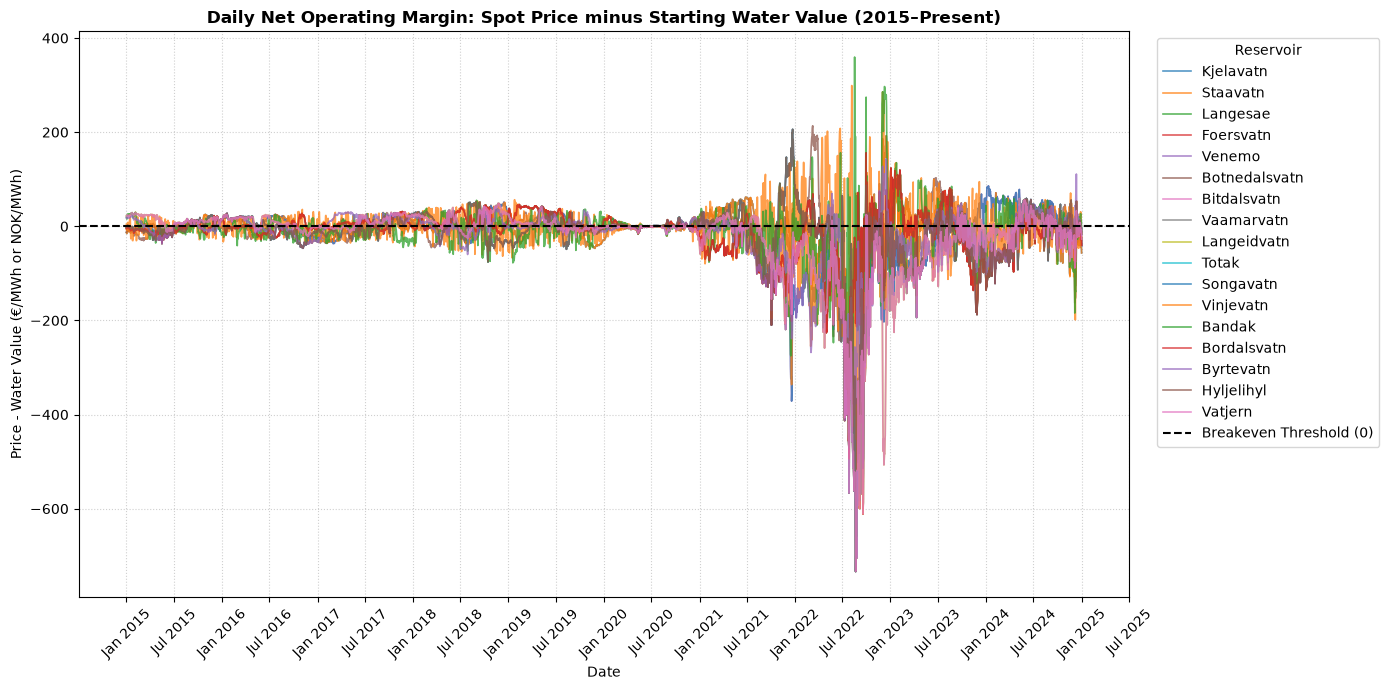

In [16]:
# Relation price and water value

data = data_loaders.DataLoader()
df_price = data.day_ahead_price_data.copy()
df_wv = data.synthetic_water_value_data.copy()

for df in (df_price, df_wv):
    if 'date' in df.columns:
        df.set_index('date', inplace=True)
    if not isinstance(df.index, pd.DatetimeIndex):
        df.index = pd.to_datetime(df.index)
    if df.index.tz is not None:
        df.index = df.index.tz_localize(None)

price_col = [col for col in df_price.columns if col != 'date'][0]
price_series = df_price[price_col]

df_wv_start = df_wv.resample('D').first()

price_daily_start = price_series.resample('D').first()

spread_df = pd.DataFrame(index=df_wv_start.index)

for res in df_wv_start.columns:
    spread_df[res] = price_daily_start - df_wv_start[res]

plt.figure(figsize=(14, 7))

for col in spread_df.columns:
    plt.plot(
        spread_df.index, 
        spread_df[col], 
        label=col, 
        alpha=0.75, 
        linewidth=1.2
    )

plt.axhline(0, color='black', linestyle='--', linewidth=1.5, label='Breakeven Threshold ($0$)')
plt.title('Daily Net Operating Margin: Spot Price minus Starting Water Value (2015–Present)', fontsize=12, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Price - Water Value (€/MWh or NOK/MWh)')
plt.grid(True, linestyle=':', alpha=0.6)


ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.xticks(rotation=45)
plt.legend(title='Reservoir', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()